# Cleaning the weather table



In [1]:
import os
os.chdir("/home/jovyan/work")

In [2]:
from pyspark.sql import SparkSession, functions as F
spark = (
    SparkSession.builder
    .appName("clean_weather_notebook")
    .config("spark.driver.memory", "6g")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)
print("driver.memory:", spark.sparkContext.getConf().get("spark.driver.memory", "NOT SET"))
spark

driver.memory: 6g


## Step 0: load the raw table
Output of `02_ingest_weather.py`

In [3]:
df = spark.read.parquet("data/processed/weather_raw")
start_count = df.count()
print("Rows read:", start_count)
df.printSchema()
df.show(5)

Rows read: 10384200
root
 |-- location_id: integer (nullable = true)
 |-- station: string (nullable = true)
 |-- station_latitude: double (nullable = true)
 |-- station_longitude: double (nullable = true)
 |-- datetime_utc: string (nullable = true)
 |-- temperature_2m: double (nullable = true)
 |-- relative_humidity_2m: double (nullable = true)
 |-- precipitation: double (nullable = true)
 |-- wind_speed_10m: double (nullable = true)
 |-- _corrupt_record: string (nullable = true)

+-----------+--------------------+------------------+--------------------+--------------------+--------------+--------------------+-------------+--------------+---------------+
|location_id|             station|  station_latitude|   station_longitude|        datetime_utc|temperature_2m|relative_humidity_2m|precipitation|wind_speed_10m|_corrupt_record|
+-----------+--------------------+------------------+--------------------+--------------------+--------------+--------------------+-------------+--------------+

## Step 0: check temporal coverage

,year,count
0,2018,1182600
1,2019,1182600
2,2020,1185840
3,2021,1182600
4,2022,1182600
5,2023,1182600
6,2024,1185840
7,2025,1182600
8,2026,916920


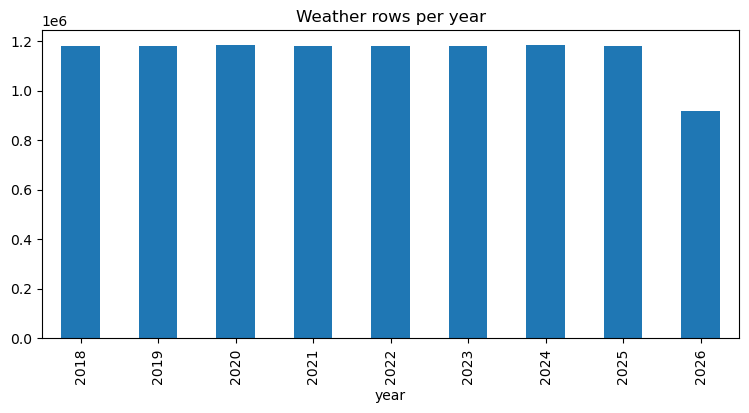

In [4]:
import pandas as pd

df = df.withColumn("year", F.substring("datetime_utc", 1, 4).cast("int"))

rows_per_year = df.groupBy("year").count().orderBy("year").toPandas()
rows_per_year.plot(kind="bar", x="year", y="count", legend=False, title="Weather rows per year", figsize=(9, 4))
rows_per_year

In [5]:
stations_per_year = (
    df.groupBy("year")
    .agg(F.countDistinct("location_id").alias("distinct_stations"))
    .orderBy("year")
)
stations_per_year.show(20)

+----+-----------------+
|year|distinct_stations|
+----+-----------------+
|2018|              135|
|2019|              135|
|2020|              135|
|2021|              135|
|2022|              135|
|2023|              135|
|2024|              135|
|2025|              135|
|2026|              135|
+----+-----------------+



## Step 1: drop corrupt rows


In [6]:
df = df.filter(F.col("_corrupt_record").isNull())
after_corrupt = df.count()
print("Dropped for being corrupt/unparseable:", start_count - after_corrupt)
print("Rows remaining:", after_corrupt)

Dropped for being corrupt/unparseable: 0
Rows remaining: 10384200


## Step 2: parse the timestamp

In [7]:
df = df.withColumn("datetime_utc_ts", F.to_timestamp("datetime_utc", "yyyy-MM-dd'T'HH:mm:ss'Z'"))
df.select("datetime_utc", "datetime_utc_ts").show(5, truncate=False)

+--------------------+-------------------+
|datetime_utc        |datetime_utc_ts    |
+--------------------+-------------------+
|2020-01-01T00:00:00Z|2020-01-01 00:00:00|
|2020-01-01T01:00:00Z|2020-01-01 01:00:00|
|2020-01-01T02:00:00Z|2020-01-01 02:00:00|
|2020-01-01T03:00:00Z|2020-01-01 03:00:00|
|2020-01-01T04:00:00Z|2020-01-01 04:00:00|
+--------------------+-------------------+
only showing top 5 rows



In [8]:
df = df.filter(F.col("datetime_utc_ts").isNotNull())
after_timestamp = df.count()
print("Dropped for an unparseable datetime:", after_corrupt - after_timestamp)
print("Rows remaining:", after_timestamp)

Dropped for an unparseable datetime: 0
Rows remaining: 10384200


## Step 3: check missing weather values


In [9]:
null_counts = df.agg(
    F.sum(F.col("temperature_2m").isNull().cast("int")).alias("null_temperature_2m"),
    F.sum(F.col("relative_humidity_2m").isNull().cast("int")).alias("null_relative_humidity_2m"),
    F.sum(F.col("precipitation").isNull().cast("int")).alias("null_precipitation"),
    F.sum(F.col("wind_speed_10m").isNull().cast("int")).alias("null_wind_speed_10m"),
).first()
for k in null_counts.asDict():
    print(k, ":", null_counts[k])

null_temperature_2m : 0
null_relative_humidity_2m : 0
null_precipitation : 0
null_wind_speed_10m : 0


## Step 4: drop physically impossible readings

In [10]:
impossible = df.filter(
    ~F.col("temperature_2m").between(-40, 50)
    | ~F.col("relative_humidity_2m").between(0, 100)
    | (F.col("precipitation") < 0)
    | (F.col("wind_speed_10m") < 0)
)
print("Example impossible rows:")
impossible.select("location_id", "datetime_utc", "temperature_2m", "relative_humidity_2m", "precipitation", "wind_speed_10m").show(5)

Example impossible rows:
+-----------+------------+--------------+--------------------+-------------+--------------+
|location_id|datetime_utc|temperature_2m|relative_humidity_2m|precipitation|wind_speed_10m|
+-----------+------------+--------------+--------------------+-------------+--------------+
+-----------+------------+--------------+--------------------+-------------+--------------+



In [11]:
df = df.filter(
    F.col("temperature_2m").between(-40, 50)
    & F.col("relative_humidity_2m").between(0, 100)
    & (F.col("precipitation") >= 0)
    & (F.col("wind_speed_10m") >= 0)
)
after_range = df.count()
print("Dropped for an impossible reading:", after_timestamp - after_range)
print("Rows remaining:", after_range)

Dropped for an impossible reading: 0
Rows remaining: 10384200


## Step 5: station consistency

In [12]:
inconsistent_stations = (
    df.groupBy("location_id")
    .agg(
        F.countDistinct("station").alias("distinct_names"),
        F.countDistinct("station_latitude").alias("distinct_lats"),
        F.countDistinct("station_longitude").alias("distinct_lons"),
    )
    .filter((F.col("distinct_names") > 1) | (F.col("distinct_lats") > 1) | (F.col("distinct_lons") > 1))
)
print("Stations with inconsistent name/coordinates:", inconsistent_stations.count())
inconsistent_stations.show()

Stations with inconsistent name/coordinates: 0
+-----------+--------------+-------------+-------------+
|location_id|distinct_names|distinct_lats|distinct_lons|
+-----------+--------------+-------------+-------------+
+-----------+--------------+-------------+-------------+



## Step 6: drop duplicates

In [13]:
df = df.dropDuplicates(["location_id", "datetime_utc_ts"])
after_dedup = df.count()
print("Dropped as duplicates (same station+UTC hour):", after_range - after_dedup)
print("Rows remaining:", after_dedup)

Dropped as duplicates (same station+UTC hour): 0
Rows remaining: 10384200


## Visualize: rows surviving each step

,step,rows
0,raw,10384200
1,drop corrupt,10384200
2,parse timestamp,10384200
3,drop impossible readings,10384200
4,drop duplicates,10384200


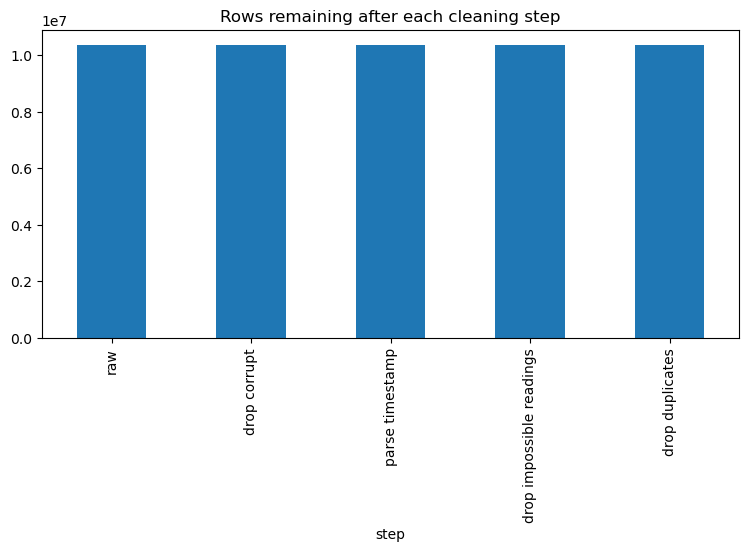

In [15]:
steps = pd.DataFrame({
    "step": ["raw", "drop corrupt", "parse timestamp", "drop impossible readings", "drop duplicates"],
    "rows": [start_count, after_corrupt, after_timestamp, after_range, after_dedup],
})
steps.plot(kind="bar", x="step", y="rows", legend=False, title="Rows remaining after each cleaning step", figsize=(9, 4))
steps

## Step 7: save the cleaned table
Only run this once you're happy with the result above -- it overwrites `data/processed/weather_clean`.

In [ ]:
clean = df.select(
    "location_id", "station", "station_latitude", "station_longitude",
    F.col("datetime_utc_ts").alias("datetime_utc"),
    "temperature_2m", "relative_humidity_2m", "precipitation", "wind_speed_10m",
)

OUT_PATH = "data/processed/weather_clean"
clean.coalesce(8).write.mode("overwrite").parquet(OUT_PATH)
print(f"Saved to {OUT_PATH}")
print("Summary: started with", start_count, "rows, ended with", after_dedup, "rows")